# Forecasting: inspect what is known at the cutoff

We follow a generated autoregressive series through fitting, joint uncertainty, chronological evaluation, and updating. The generating model gives an oracle reference, while held-out observations show how much random variation remains around even a correct forecast.

The same forecast contract also supports multivariate series and explicit future covariates. We inspect those separately instead of treating every adapter as interchangeable. [Full model catalog](../time_series_forecasting.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import forecasting as ts

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## One cutoff, one future segment

Generate $y_t=0.8y_{t-1}+\epsilon_t$, with innovation standard deviation 0.3. Only the first 240 observations are used to fit the AR model. Its oracle conditional mean is $0.8^h y_{239}$; a realized future need not track that mean closely.

Forecast rows are `(horizon, target)`. The plot distinguishes training history, withheld observations, and pointwise forecast intervals. Uncertainty is conditional on fitted parameters.

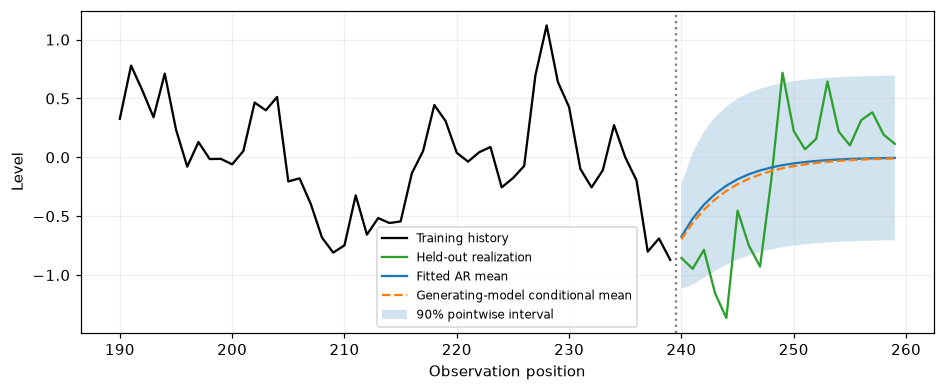

,fitted mean,oracle mean,fitted variance,oracle variance
lead,,,,
1,-0.673142,-0.696303,0.072700,0.090000
5,-0.240823,-0.285206,0.167055,0.223156
10,-0.066633,-0.093456,0.179844,0.247118
20,-0.005101,-0.010035,0.180898,0.249967


In [2]:
phi, innovation_sd = .8, .3
y = np.zeros(360)
for t in range(1, len(y)):
    y[t] = phi*y[t-1] + rng.normal(scale=innovation_sd)
cutoff, horizon = 240, 20
train = ts.TimeSeries(y[:cutoff], names=("level",))
fitted = ts.ARForecaster(trend="n").fit(train)
forecast = fitted.forecast(horizon)
lead = np.arange(1, horizon+1)
oracle_mean = phi**lead*y[cutoff-1]
oracle_variance = innovation_sd**2*(1-phi**(2*lead))/(1-phi**2)
bounds = forecast.interval(.9)[:, 0]
fig, ax = plt.subplots()
ax.plot(np.arange(cutoff-50, cutoff), y[cutoff-50:cutoff], color="black", label="Training history")
ax.plot(np.arange(cutoff, cutoff+horizon), y[cutoff:cutoff+horizon], color="tab:green", label="Held-out realization")
ax.plot(forecast.horizon.timestamps, forecast.mean()[:, 0], label="Fitted AR mean")
ax.plot(forecast.horizon.timestamps, oracle_mean, "--", label="Generating-model conditional mean")
ax.fill_between(forecast.horizon.timestamps, bounds[:, 0], bounds[:, 1], alpha=.2, label="90% pointwise interval")
ax.axvline(cutoff-.5, color="gray", linestyle=":")
ax.set(xlabel="Observation position", ylabel="Level")
ax.legend(fontsize=8)
plt.show()
pd.DataFrame({"lead": lead[[0, 4, 9, 19]], "fitted mean": forecast.mean()[[0, 4, 9, 19], 0],
              "oracle mean": oracle_mean[[0, 4, 9, 19]], "fitted variance": forecast.variance()[[0, 4, 9, 19], 0],
              "oracle variance": oracle_variance[[0, 4, 9, 19]]}).set_index("lead")

## AR forecasts do include cross-time uncertainty

Convexity's statsmodels AR adapter supplies a joint Gaussian forecast law. The pointwise intervals in the first plot show only its diagonal; `covariance()` and `sample()` retain dependence across future times.

To see why that matters, compare the distribution of the sum of twenty future values with an artificial independent-marginal construction. The latter has the same marginal means and variances but discards persistence, changing the uncertainty of a path-level quantity.

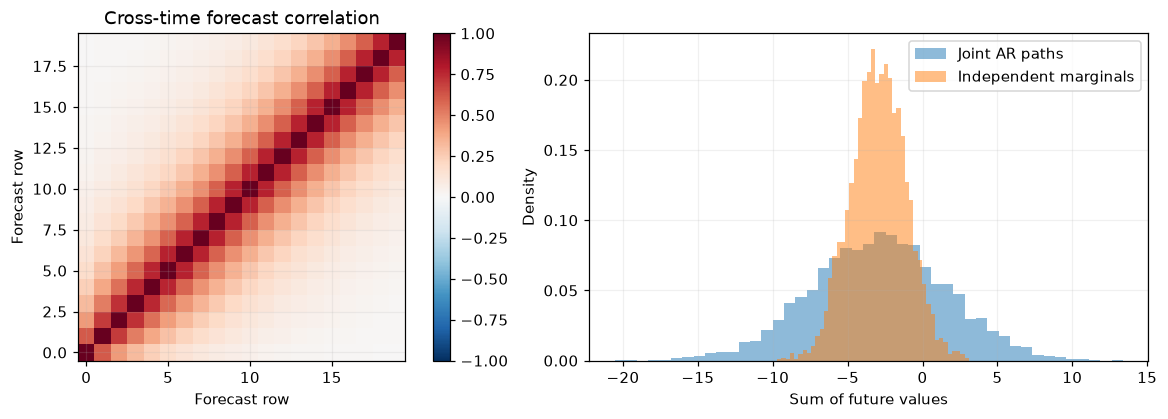

,quantity,joint Monte Carlo probability,independent-marginal probability
0,sum above 2,0.13975,0.00575
1,all future values positive,0.00000,0.00000


In [3]:
joint_draws = forecast.sample(4000, rng=np.random.default_rng(7))
independent_draws = forecast.mean()[None, :, :] + np.sqrt(forecast.variance())[None, :, :]*np.random.default_rng(8).normal(size=joint_draws.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), layout="constrained")
image = axes[0].imshow(forecast.correlation(), origin="lower", vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set(xlabel="Forecast row", ylabel="Forecast row", title="Cross-time forecast correlation")
fig.colorbar(image, ax=axes[0])
axes[1].hist(joint_draws[:, :, 0].sum(axis=1), bins=45, density=True, alpha=.5, label="Joint AR paths")
axes[1].hist(independent_draws[:, :, 0].sum(axis=1), bins=45, density=True, alpha=.5, label="Independent marginals")
axes[1].set(xlabel="Sum of future values", ylabel="Density")
axes[1].legend()
plt.show()
pd.DataFrame({"quantity": ["sum above 2", "all future values positive"],
    "joint Monte Carlo probability": [np.mean(joint_draws[:, :, 0].sum(axis=1)>2), np.mean(np.all(joint_draws[:, :, 0]>0, axis=1))],
    "independent-marginal probability": [np.mean(independent_draws[:, :, 0].sum(axis=1)>2), np.mean(np.all(independent_draws[:, :, 0]>0, axis=1))]})

## Evaluate at many historical cutoffs

`compare` refits each model inside each training prefix. These backtests use only the first 300 observations; the final 60 remain outside this model-comparison experiment. Explicit baselines make the comparison interpretable rather than ranking only sophisticated models.

RMSE is reported separately by lead. Calibration asks what fraction of observations falls below each predicted quantile. There are relatively few origins, and multi-step errors overlap, so the calibration plot is descriptive rather than a confidence analysis.

,RMSE,MAE,forecast origins
AR(1),0.429529,0.343215,32.0
Lag regression,0.429769,0.337467,32.0
Last value,0.550131,0.438332,32.0
Trailing mean,0.499166,0.398445,32.0


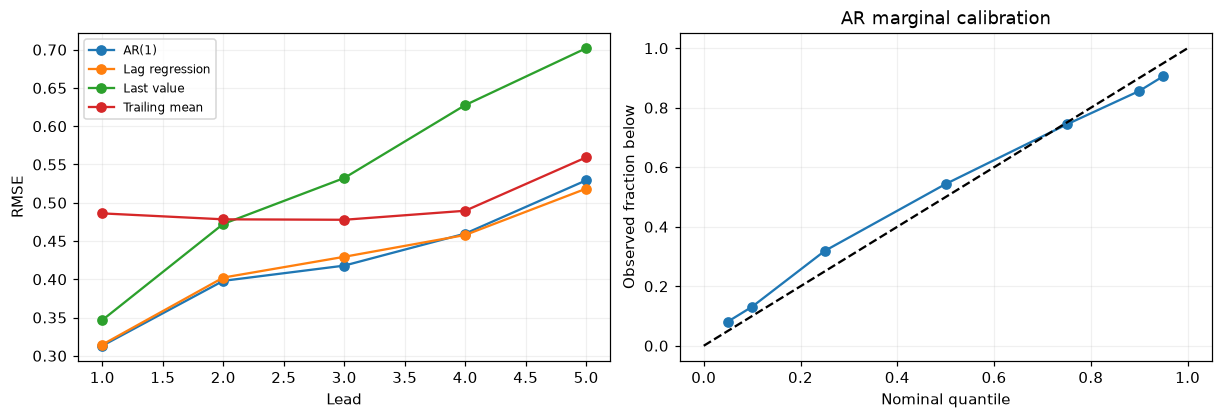

In [4]:
models = {"AR(1)": ts.ARForecaster(trend="n"), "Lag regression": ts.RegressionForecaster(),
          "Last value": ts.NaiveForecaster(), "Trailing mean": ts.MovingMeanForecaster(window=30)}
backtests = ts.compare(models, y[:300], include_baselines=False, horizon=5, initial_window=140, step=5)
display(pd.DataFrame({label: {"RMSE": float(result.score("rmse")), "MAE": float(result.score("mae")),
    "forecast origins": len(result.records)} for label, result in backtests.items()}).T)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
for label, result in backtests.items():
    axes[0].plot(np.arange(1, 6), result.score("rmse", by_horizon=True)[:, 0], marker="o", label=label)
axes[0].set(xlabel="Lead", ylabel="RMSE")
axes[0].legend(fontsize=8)
calibration = backtests["AR(1)"].calibration(levels=(.05, .1, .25, .5, .75, .9, .95))
axes[1].plot(calibration[:, 0], calibration[:, 1], "o-")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set(xlabel="Nominal quantile", ylabel="Observed fraction below", title="AR marginal calibration")
plt.show()

## Updating uses actual new observations

An incremental update assimilates new measurements while retaining the fitted parameters. A refit estimates parameters again using the expanded history. Both operations should use the newly observed data, rather than repeated copies of the last training value.

All forecasts below refer to the same future rows. The original model's longer-horizon forecast shows what was known before the intervening ten observations arrived.

In [5]:
new_data = y[cutoff:cutoff+10]
incremental = fitted.update(new_data, mode="incremental")
refitted = fitted.update(new_data, mode="refit")
old_prediction = fitted.forecast(np.arange(11, 16))
pd.DataFrame({"future position": np.arange(cutoff+10, cutoff+15),
              "forecast before new observations": old_prediction.point[:, 0],
              "incrementally updated": incremental.predict(5)[:, 0],
              "refitted": refitted.predict(5)[:, 0],
              "held-out actual": y[cutoff+10:cutoff+15]})

,future position,forecast before new observations,incrementally updated,refitted,held-out actual
0,250,-0.051533,0.555604,0.561011,0.223252
1,251,-0.039855,0.429698,0.438102,0.068127
2,252,-0.030824,0.332324,0.342120,0.156968
3,253,-0.023839,0.257016,0.267167,0.644184
4,254,-0.018437,0.198773,0.208635,0.219290


## Known-future inputs describe scenarios, not information inferred from the target

A deterministic calendar feature is available beyond the training cutoff. SARIMAX can use it as an exogenous regressor. Changing supplied future values produces a conditional scenario forecast; it does not estimate the probability of that scenario.

Convexity requires future covariates for every intervening row through the largest requested lead, even when the requested horizon is sparse.

In [6]:
calendar = np.sin(2*np.pi*np.arange(len(y))/12)[:, None]
seasonal_y = y + 1.2*calendar[:, 0]
conditional = ts.SARIMAXForecaster(order=(1, 0, 0), trend="n").fit(
    ts.TimeSeries(seasonal_y[:240], covariates=ts.Covariates(known_future=calendar[:240])))
calendar_forecast = conditional.forecast([1, 6, 12], covariates=calendar[240:252])
zero_scenario = conditional.forecast([1, 6, 12], covariates=np.zeros((12, 1)))
pd.DataFrame({"lead": [1, 6, 12], "calendar scenario": calendar_forecast.point[:, 0],
              "zero-input scenario": zero_scenario.point[:, 0]})

,lead,calendar scenario,zero-input scenario
0,1,-0.684211,-0.684211
1,6,0.396344,-0.189768
2,12,-0.626837,-0.040725


## Multiple targets add another dependence axis

Generate a stable two-variable VAR with correlated innovations and cross-lag effects. Its forecast law includes dependence across targets **and** across time. Flattening for covariance follows time-major order: `(lead 1, target 0)`, `(lead 1, target 1)`, then lead 2.

The displayed first two leads show both kinds of dependence. A pair of separately fitted univariate forecasters would not infer these cross-target covariances.

In [7]:
transition = np.array([[.65, .2], [-.1, .6]])
innovations = rng.multivariate_normal([0., 0.], [[.09, .035], [.035, .06]], 350)
vector = np.zeros((350, 2))
for t in range(1, len(vector)):
    vector[t] = transition @ vector[t-1]+innovations[t]
joint = ts.VARForecaster().fit(vector[:300]).forecast(8)
labels = ["lead 1 / target 0", "lead 1 / target 1", "lead 2 / target 0", "lead 2 / target 1"]
pd.DataFrame(joint.covariance()[:4, :4], index=labels, columns=labels)

,lead 1 / target 0,lead 1 / target 1,lead 2 / target 0,lead 2 / target 1
lead 1 / target 0,0.094744,0.039083,0.060769,0.006909
lead 1 / target 1,0.039083,0.063392,0.024062,0.025545
lead 2 / target 0,0.060769,0.024062,0.133743,0.043031
lead 2 / target 1,0.006909,0.025545,0.043031,0.074793


The same interface covers broader neural and pretrained models, but they need their own data-size and uncertainty inspection. The [advanced example](../examples/forecasting_advanced.py) and [checkpoint example](../examples/forecasting_pretrained.py) provide executable entry points; this notebook makes no comparison claims about models it has not run. Portable artifact round trips belong in tests, while the fitted numerical quantities above are the subject of inspection here.